### **11. Write and execute a program for image morphological operations erosion and dilation.**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data,color

In [2]:
# Load Image and make it binary for morphology
img = data.camera()
_, binary_img = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

# # Load the astronaut image and convert to grayscale
# img_rgb = data.astronaut()
# img_gray = color.rgb2gray(img_rgb)
# img_gray = (img_gray * 255).astype(np.uint8)

In [3]:
# Define Structuring Element (Kernel)
# 5x5 Rectangular Kernel
kernel = np.ones((5, 5), np.uint8)

Erosion (Shrinks bright regions)

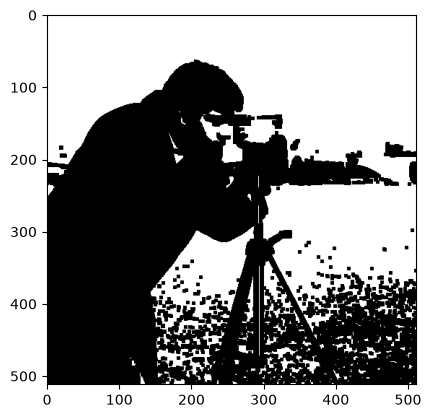

In [4]:
erosion = cv2.erode(binary_img, kernel, iterations=1)
plt.imshow(erosion, cmap='gray')

Dilation (Expands bright regions)

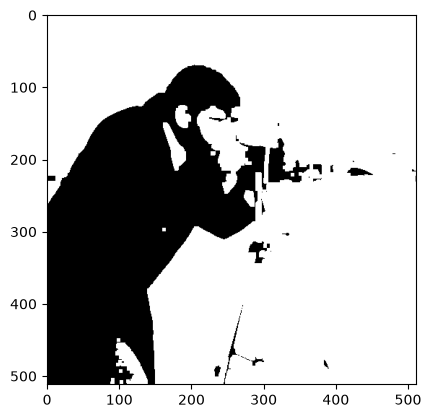

In [5]:
dilation = cv2.dilate(binary_img, kernel, iterations=1)
plt.imshow(dilation, cmap='gray')

Opening (Erosion followed by Dilation) - Removes small white noise

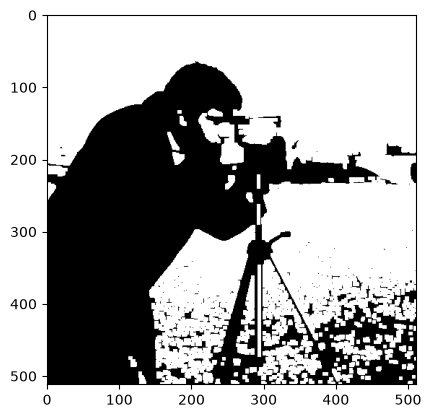

In [6]:
opening = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)
plt.imshow(opening, cmap='gray')

Closing (Dilation followed by Erosion) - Closes small black holes

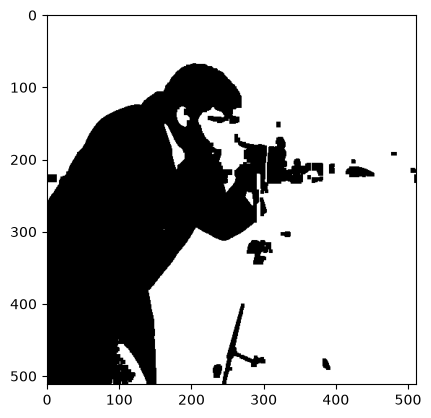

In [7]:
closing = cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel)
plt.imshow(closing, cmap='gray')

hit and miss operation

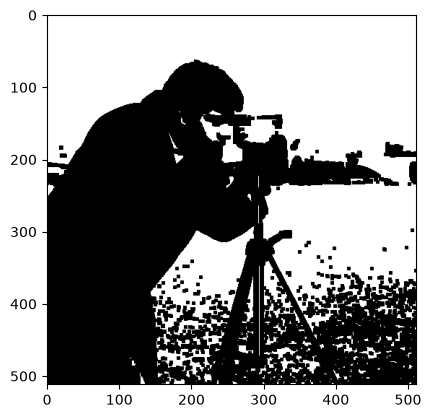

In [8]:

hitmiss = cv2.morphologyEx(binary_img, cv2.MORPH_HITMISS, kernel)
plt.imshow(hitmiss, cmap='gray')

Connected Components

Number of connected components (including background): 94


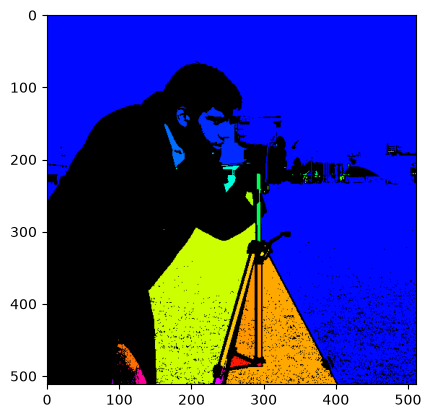

In [9]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary_img, connectivity=8)

# Create color map for connected components
label_hue = np.uint8(179 * labels / np.max(labels))
blank_ch = 255 * np.ones_like(label_hue)
labeled_img = cv2.merge([label_hue, blank_ch, blank_ch])
labeled_img = cv2.cvtColor(labeled_img, cv2.COLOR_HSV2BGR)
labeled_img[label_hue == 0] = 0

print(f"Number of connected components (including background): {num_labels}")
plt.imshow(labeled_img, cmap='gray')

Internal Boundary

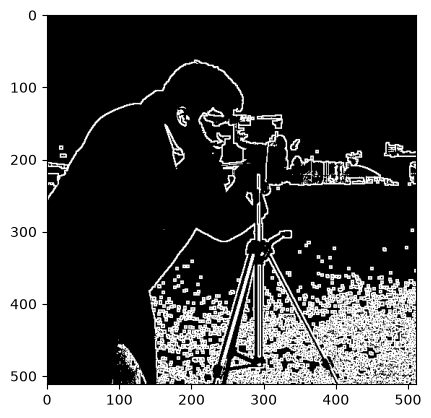

In [10]:
#    Boundary = A - (A ⊖ B)
eroded = cv2.erode(binary_img, kernel, iterations=1)
internal_boundary = cv2.subtract(binary_img, eroded)
plt.imshow(internal_boundary, cmap='gray')